# Fresh Eyes on CMIP - Aggregating Data Analysis Tools
Following main.ipynb, First start for ocean biogeochemistry tools with integrated net primary production in the global ocean. (Pg C yr-1)

## Introduction

This notebook illustrates how to easily access [CMIP7](https://wcrp-cmip.github.io/cmip7-guidance/docs/CMIP7/Guidance_for_users/) data and perform basic data analysis tasks.

In [1]:
import requests
import fsspec

import numpy as np
import xarray

import matplotlib.pyplot as plt

## Data search in the ESGF

CMIP7 model output is available through a distributed data archive developed and operated by the [Earth System Grid Federation (ESGF)](https://esgf.github.io/). The data are hosted across a network of nodes located at climate modelling centres and data centres around the world.

ESGF is an international collaboration of groups, agencies, and institutions dedicated to developing and operating a long-term system for managing, accessing, and analysing climate data. Its architecture is based on a network of distributed nodes. Data nodes host the available datasets, while index nodes maintain catalogues that allow users to search for data across the network.

Users can connect to any ESGF node through a web browser or a desktop client to search for and access data across the federation. However, individual nodes may occasionally become unavailable, which can temporarily prevent access to some datasets.

There are three options for accessing the data:

1. Metagrid - Metagrid provides a web interface for searching and downloading ESGF data. It is best suited for browsing datasets and downloading a small number of files. Users can search across the distributed archive as though the data were stored in a single central location. Available Metagrid portals:
   - [West index (ORNL)](https://metagrid.esgf-west.org/)
   - [West index (NERSC)](https://metagrid-nersc.west.esgf.io/)
   - [East index](https://metagrid-ceda.east.esgf.io/search)

2. APIs - For larger searches or bulk downloads, automated tools may be more suitable. Several software packages are available for interacting with the ESGF indexes and retrieving data.
   - [ESGpull](https://esgf.github.io/esgf-download/) - Version 0.10.0 supports interaction with the CMIP7 indexes but requires some configuration. Refer to the documentation for setup instructions.
   - [intake-esgf](https://github.com/esgf2-us/intake-esgf) - Version 2026.9.4 supports interaction with the CMIP7 indexes.

In [13]:
from pathlib import Path
import requests

search_url = "https://esgf.ceda.ac.uk/esg-search/search"

params = {
    "type": "File",
    "format": "application/solr+json",
    "project": "CMIP7",
    "source_id": "UKESM1-3-LL",
    "experiment_id": "historical",
    "variant_label": "r1i1p1f2",
    "variable_id": "intpp",
    "frequency": "mon",
    "grid_label": "g126",
    "limit": 1000,
}

response = requests.get(search_url, params=params, timeout=60)
response.raise_for_status()
docs = response.json()["response"]["docs"]

# Keep files from the same CEDA dataset directory as your example.
dataset_path = (
    "/CMIP7/CMIP/UKNCSP/UKESM1-3-LL/historical/"
    "r1i1p1f2/glb/mon/intpp/tavg-u-hxy-sea/g126/"
)

urls = set()
for doc in docs:
    for item in doc.get("url", []):
        url, _, service = item.partition("|")
        if service == "HTTPServer" and dataset_path in url:
            urls.add(url)

print(f"Found {len(urls)} matching files")

for url in sorted(urls):
    filename = Path(url).name
    print(f"Downloading {filename}")

    with requests.get(url, stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(filename, "wb") as f:
            for chunk in r.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)

Found 0 matching files


In [2]:
UKCM2_0_LL = [
    "https://esgf.ceda.ac.uk/data/esg_cmip7/MIP-DRS7/CMIP7/CMIP/UKNCSP/UKESM1-3-LL/historical/r1i1p1f2/glb/mon/intpp/tavg-u-hxy-sea/g126/files/d20261004/intpp_tavg-u-hxy-sea_mon_glb_g126_UKESM1-3-LL_historical_r1i1p1f2_185001-194912.nc",
    "https://esgf.ceda.ac.uk/data/esg_cmip7/MIP-DRS7/CMIP7/CMIP/UKNCSP/UKESM1-3-LL/historical/r1i1p1f2/glb/mon/intpp/tavg-u-hxy-sea/g126/files/d20261004/intpp_tavg-u-hxy-sea_mon_glb_g126_UKESM1-3-LL_historical_r1i1p1f2_195001-202112.nc",
]

for url in UKCM2_0_LL:
    filename = url.split("/")[-1] # obtain the local filename
    with open(filename, "wb") as f:
        f.write(requests.get(url).content)

For this example notebook, we will perform the downloads using simple Python code based on the `requests` module.

In [3]:
for url in UKCM2_0_LL:
    filename = url.split("/")[-1] # obtain the local filename
    with open(filename, "wb") as f:
        f.write(requests.get(url).content)

## A very simple climate analysis task

Now that we have obtained our datasets of interest, it is time to start analyzing them. For this task, we will use [xarray](https://docs.xarray.dev/en/stable/), although users are free to choose whichever data analysis package they prefer.

Rather than dealing with each file separately, we instruct xarray to construct a single dataset from the two original source files. We achieve this with the [open_mfdataset](https://docs.xarray.dev/en/stable/generated/xarray.open_mfdataset.html) function.

In [4]:
ds = xarray.open_mfdataset(
    [f.split("/")[-1] for f in UKCM2_0_LL],
    coords="minimal", compat="no_conflicts").chunk({"time": 1032})


/tmp/ipykernel_130/1155303477.py:1: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  ds = xarray.open_mfdataset(
/tmp/ipykernel_130/1155303477.py:3: UserWarning: The specified chunks separate the stored chunks along dimension "0" starting at index 1032. This could degrade performance. Instead, consider rechunking after loading.
  coords="minimal", compat="no_conflicts").chunk({"time": 1032})


We now have our data loaded into xarray, so we can start analyzing it. As a simple example, we will compute and plot the monthly mean and the 12-month rolling mean of the surface temperature simulated by the `UKCM2_0_LL` climate model.

To account for the variation in grid cell area with latitude, we will weight the surface temperature by the cosine of latitude when computing the spatial mean. The next cell shows the results.

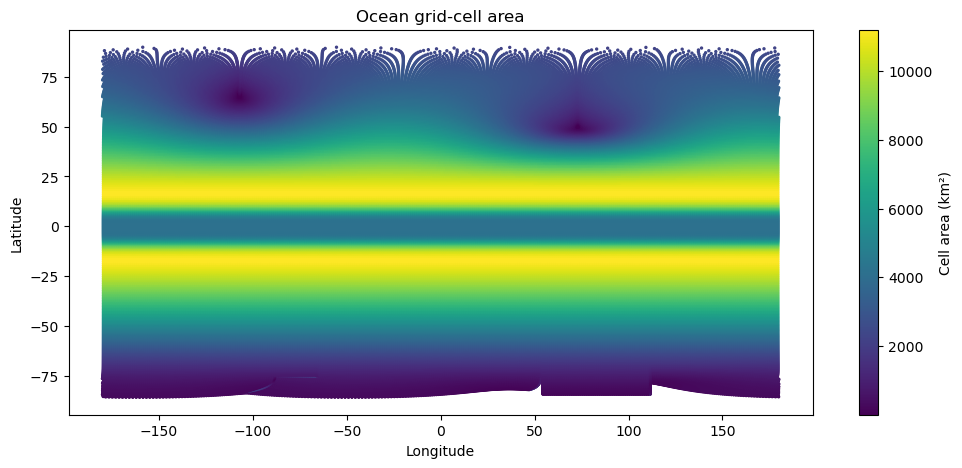

In [9]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

# Spatial dimensions of intpp
spatial_dims = [d for d in ds["intpp"].dims if d != "time"]

latv = ds["vertices_latitude"]
lonv = ds["vertices_longitude"]

# Find the dimension that indexes the cell corners
vertex_dim = next(d for d in latv.dims if d not in ds["intpp"].dims)

# If vertices vary over time, use the first time slice
if "time" in latv.dims:
    latv = latv.isel(time=0, drop=True)
    lonv = lonv.isel(time=0, drop=True)

# Convert corner coordinates from degrees to radians
lat = np.deg2rad(latv.transpose(*spatial_dims, vertex_dim).to_numpy())
lon = np.deg2rad(lonv.transpose(*spatial_dims, vertex_dim).to_numpy())

# Convert corners to 3D points on a unit sphere
xyz = np.stack(
    [np.cos(lat) * np.cos(lon),
     np.cos(lat) * np.sin(lon),
     np.sin(lat)],
    axis=-1,
)

# Calculate spherical polygon area, in steradians
area_sr = np.zeros(xyz.shape[:-2])
a = xyz[..., 0, :]

for k in range(1, xyz.shape[-2] - 1):
    b, c = xyz[..., k, :], xyz[..., k + 1, :]
    numerator = np.abs(np.sum(a * np.cross(b, c), axis=-1))
    denominator = (
        1 + np.sum(a * b, axis=-1)
        + np.sum(b * c, axis=-1)
        + np.sum(c * a, axis=-1)
    )
    area_sr += 2 * np.arctan2(numerator, denominator)

# Convert steradians to km²
area_km2 = xr.DataArray(
    area_sr * (6371**2),
    dims=spatial_dims,
    name="cell_area",
    attrs={"units": "km2"},
)

# Plot cell areas at their grid-cell centers
latitude = ds["latitude"]
longitude = ds["longitude"]

if "time" in latitude.dims:
    latitude = latitude.isel(time=0)
    longitude = longitude.isel(time=0)

plt.figure(figsize=(12, 5))
plt.scatter(
    longitude.values,
    latitude.values,
    c=area_km2.values,
    s=2,
    cmap="viridis",
    rasterized=True,
)
plt.colorbar(label="Cell area (km²)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Ocean grid-cell area")
plt.show()

This step is needed to calculate cell area of the grid. Because we want to integrate global net pripary production.
Original unit is mmol C m-2 s-1, we want Pg C y-1. That's why we do multiplication with the cell area.

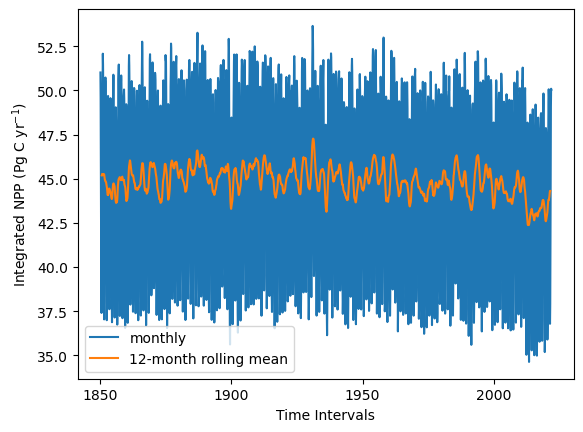

In [11]:
seconds_per_year = 365.25 * 86400

global_npp = (
    (ds["intpp"] * area_km2 * 1e6).sum(["j", "i"])
    * 12.011 * seconds_per_year / 1e15
)

global_npp.plot(label="monthly")
global_npp.rolling(time=12, center=True).mean().plot(
    label="12-month rolling mean"
)

plt.ylabel("Integrated NPP (Pg C yr$^{-1}$)")
plt.legend()
plt.show()